# Test xReceiver Models

In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/xReceiver
/Users/svasquez/driblab/dl-vision


# Load Data from Match_id

In [2]:
import json
import pickle
import pandas as pd

In [3]:
!pwd

/Users/svasquez/driblab/dl-vision


In [3]:
from xgboost_model import XGBoostModel

model_path="models/xgb_model_no_pc.pkl"
xgb_model = XGBoostModel(model_path)

IMPORTING xR_get_features2


In [8]:
xgb_model.features_cols

['distance',
 'theta1',
 'theta2',
 'dir_angle',
 'giver_coord.x',
 'giver_coord.y',
 'receiver_coord.x',
 'receiver_coord.y',
 'giver_speed',
 'receiver_speed',
 'tm_count_5',
 'tm_count_10',
 'opp_count_2',
 'opp_count_5',
 'opp_count_10',
 'dist_giv_sideline',
 'dist_rec_sideline',
 'num_opp2plyr_goal_giv',
 'num_opp2plyr_goal_rec',
 'dist_giv_goal',
 'dist_rec_goal',
 'dist_opponent_giv',
 'dist_opponent_rec',
 'opp_in_corridor_count',
 'dist2offside',
 'offside']

In [4]:

match_id = 666385
xgb_model.load_data(match_id=match_id)

In [5]:
features = xgb_model.get_features(row_num=20, plyr_id=1159683)
xR_pred, class_pred = xgb_model.predict(features)

print(f"Expected Receiver prob {xR_pred}")
print(f"Class prediction {class_pred}")


Expected Receiver prob 0.24072857201099396
Class prediction 0


{'data': {'3651': [{'x': 63.34, 'y': 55.66, 'vis': True, 'id': 45067}, {'x': 73.9, 'y': 28.1, 'vis': True, 'id': 38689}, {'x': 53.7, 'y': 49.3, 'vis': True, 'id': 1157794}, {'x': 7.0, 'y': 28.32, 'vis': False, 'id': 1276588}, {'x': 64.11, 'y': 10.09, 'vis': True, 'id': 1610030}, {'x': 64.79, 'y': 19.43, 'vis': True, 'id': 69811}, {'x': 73.74, 'y': 45.43, 'vis': True, 'id': 1329659}, {'x': 48.25, 'y': 46.92, 'vis': True, 'id': 1263688}, {'x': 55.68, 'y': 33.89, 'vis': True, 'id': 239959}, {'x': 50.91, 'y': 45.96, 'vis': False, 'id': 1219428}, {'x': 49.54, 'y': 29.24, 'vis': False, 'id': 1159675}], '3659': [{'x': 75.68, 'y': 20.18, 'vis': True, 'id': 1267742}, {'x': 65.88, 'y': 17.9, 'vis': True, 'id': 1312313}, {'x': 50.18, 'y': 41.71, 'vis': True, 'id': 1302464}, {'x': 92.76, 'y': 36.46, 'vis': False, 'id': 240070}, {'x': 74.25, 'y': 35.53, 'vis': True, 'id': 69834}, {'x': 67.92, 'y': 28.93, 'vis': True, 'id': 69716}, {'x': 67.32, 'y': 45.34, 'vis': True, 'id': 1157731}, {'x': 64.91, '

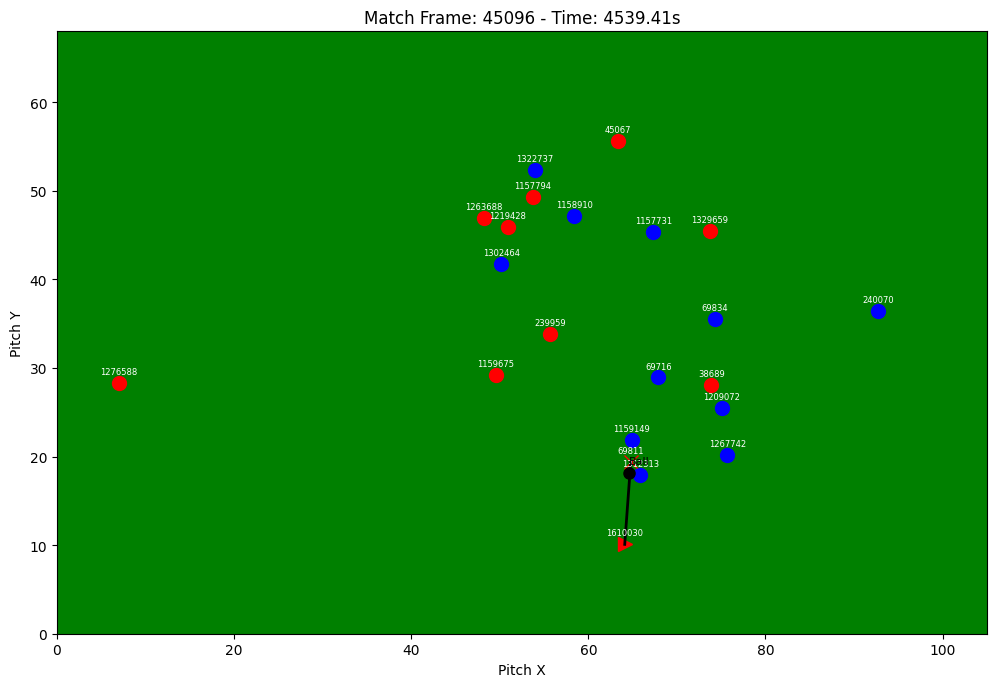

In [ ]:
from visual import Visualizer

visualizer = Visualizer(xgb_model)
visualizer.set_frame(row_num=45096)
fig = visualizer.plot_frame()

    

## TEst Model

In [6]:
# Plot a pass

row_num = 20 

merged_row =xgb_model.merged_jsonl[row_num]

print(merged_row)

{'data': {'3651': [{'x': 53.09, 'y': 39.71, 'vis': False, 'id': 1159683}, {'x': 46.74, 'y': 40.89, 'vis': False, 'id': 45067}, {'x': 52.53, 'y': 38.69, 'vis': False, 'id': 1157794}, {'x': 94.54, 'y': 34.16, 'vis': False, 'id': 1276588}, {'x': 51.77, 'y': 36.93, 'vis': False, 'id': 69811}, {'x': 51.85, 'y': 43.46, 'vis': False, 'id': 1329659}, {'x': 54.07, 'y': 32.77, 'vis': False, 'id': 1263688}, {'x': 51.44, 'y': 40.21, 'vis': False, 'id': 239959}, {'x': 52.68, 'y': 34.77, 'vis': False, 'id': 151904}, {'x': 52.71, 'y': 41.11, 'vis': False, 'id': 1264355}, {'x': 53.96, 'y': 38.69, 'vis': False, 'id': 1159675}], '3659': [{'x': 49.81, 'y': 39.42, 'vis': False, 'id': 1267742}, {'x': 4.05, 'y': 40.52, 'vis': False, 'id': 240070}, {'x': 50.19, 'y': 40.37, 'vis': False, 'id': 69834}, {'x': 43.76, 'y': 35.45, 'vis': False, 'id': 69716}, {'x': 51.0, 'y': 37.34, 'vis': False, 'id': 1166686}, {'x': 50.9, 'y': 39.48, 'vis': False, 'id': 195680}, {'x': 50.92, 'y': 34.7, 'vis': False, 'id': 1157731

In [ ]:
# Load xgboost model
import joblib

xgb_model = joblib.load('stats/xReceiver/models/xgb_model_no_pc.pkl')

xgb_features = xgb_model.get_booster().feature_names



In [22]:
import pandas as pd


X = features.copy()


X_df = pd.DataFrame([X])

X_df = X_df[xgb_features]


# Predict the probability of pass success (xP)
xP_pred = xgb_model.predict_proba(X_df)[:, 1]

# Predict the class (success/failure)
class_pred = xgb_model.predict(X_df)

# Print predictions
print(f"Predicted xP (Probability of Success): {xP_pred[0]:.2f}")
print(f"Predicted Class (0=Unsuccessful, 1=Successful): {class_pred[0]}")

Predicted xP (Probability of Success): 0.24
Predicted Class (0=Unsuccessful, 1=Successful): 0
